# Project 1, Part A (continued): V1 to V5, looking inside

Needs the checkpoints and `my_models.py` from P1_A. For each figure, state the selection rule, the normalization, and a supported claim.
Leave crops flagged by `HAS_PERSON` out of every figure.

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Mounted at /content/drive
project folder: /content/drive/MyDrive/p1
p1_utils: project folder /content/drive/MyDrive/p1 | OpenCV 4.14.0 | Colab: True
versions: python 3.13.16, torch 2.14.1+cu130, torchvision 0.29.1+cu130, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu Tesla T4


{'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'torchvision': '0.29.1+cu130',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'Tesla T4'}

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['bicycle', 'bottle', 'chair', 'pottedplant', 'tvmonitor']     # TODO: your five classes (same in every notebook)

device: cuda


In [3]:
X64, y, img_id, is_test = load_crops(64)          # cached by P1_0
idx_train, idx_val, idx_test = make_splits(img_id, is_test)
HAS_PERSON = person_flags()                       # leave these crops out of every figure
print(len(idx_train), 'train,', len(idx_val), 'validation,', len(idx_test), 'test crops')

7541 train, 797 validation, 8381 test crops


In [4]:
try:                                              # your classes and helpers, written in P1_A
    from my_models import *
except ImportError:
    print('my_models.py not found yet: write it in P1_A_Classifier_Ladder')

In [5]:
# TODO Load your A1 (three L2 settings), A3, A4, A5 and A6-H from CKPT_DIR.
# Functions: model.load_state_dict(torch.load(path, map_location=DEV)); model.to(DEV).eval()
  # TODO Load your A1 (three L2 settings), A3, A4, A5 and A6-H from CKPT_DIR.

# A1: three L2 settings
a1_models = {}

for l2 in [0.01, 1, 10]:
    model = nn.Linear(3072, 19).to(DEV)
    path = os.path.join(CKPT_DIR, f"a1_l2_{l2:g}.pt")

    model.load_state_dict(torch.load(path, map_location=DEV))
    model.to(DEV).eval()

    a1_models[l2] = model
#i have some problem loading A3,A4,and A5 so i define the whole class before loading, and the code is right before the V3, V4 and V5 section.


In [6]:
# TODO Reload check, before using any reloaded model: recompute its VOC test mean per-class accuracy (19 classes)
# and confirm it matches Table 1 from P1_A. If it does not, this notebook's preprocessing differs from P1_A's
# (for example, A6 needs its checkpoint's mean and std, not the usual ImageNet values): fix that first.
print( list(a1_models))
# A1 Reload Check: VOC test mean per-class accuracy (19 classes)

import cv2
import numpy as np
import torch

# 1. Recreate the same 32x32 images used in A1
X32 = np.stack([
    cv2.resize(im, (32, 32), interpolation=cv2.INTER_AREA)
    for im in X64
])

# 2. Use the training statistics from A1
X_train32 = X32[idx_train]
chan_mean = X_train32.reshape(-1, 3).mean(axis=0)
chan_std = X_train32.reshape(-1, 3).std(axis=0)

X32_std = (X32 - chan_mean) / chan_std

# 3. Prepare test data
X_test = torch.from_numpy(
    X32_std[idx_test].reshape(len(idx_test), -1)
).float().to(DEV)

y_test = torch.from_numpy(y[idx_test]).long().to(DEV)

# 4. Evaluate the three A1 models
for l2, model in a1_models.items():

    model.eval()

    with torch.no_grad():
        predictions = model(X_test).argmax(dim=1)

    class_accuracies = []

    for c in range(19):
        mask = (y_test == c)

        if mask.sum() > 0:
            accuracy = (
                predictions[mask] == y_test[mask]
            ).float().mean().item()

            class_accuracies.append(accuracy)

    mean_per_class_accuracy = np.mean(class_accuracies)

    print(
        f"A1 L2={l2}: "
        f"VOC test mean per-class accuracy = "
        f"{mean_per_class_accuracy:.4f}"
    )

[0.01, 1, 10]
A1 L2=0.01: VOC test mean per-class accuracy = 0.2201
A1 L2=1: VOC test mean per-class accuracy = 0.1706
A1 L2=10: VOC test mean per-class accuracy = 0.1290


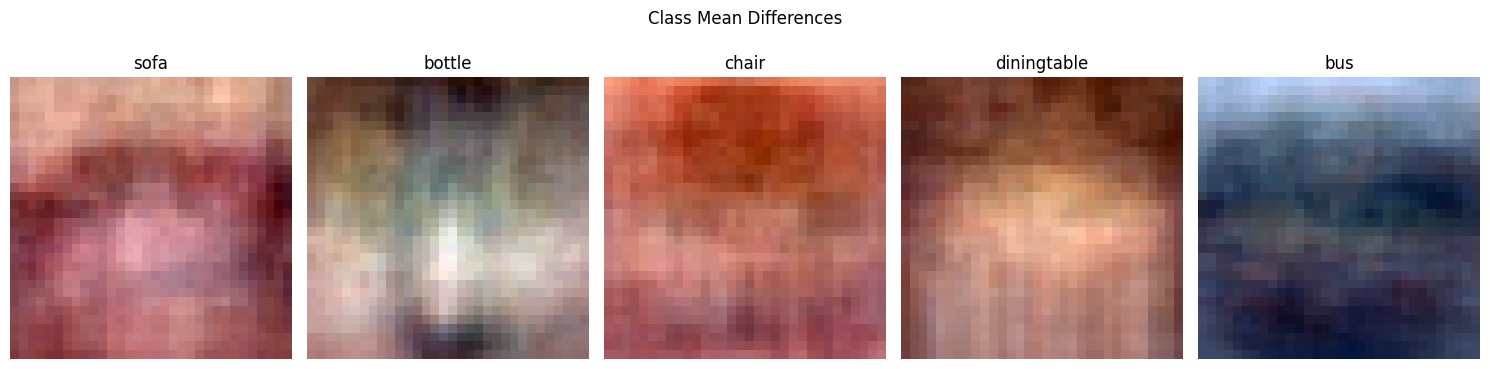

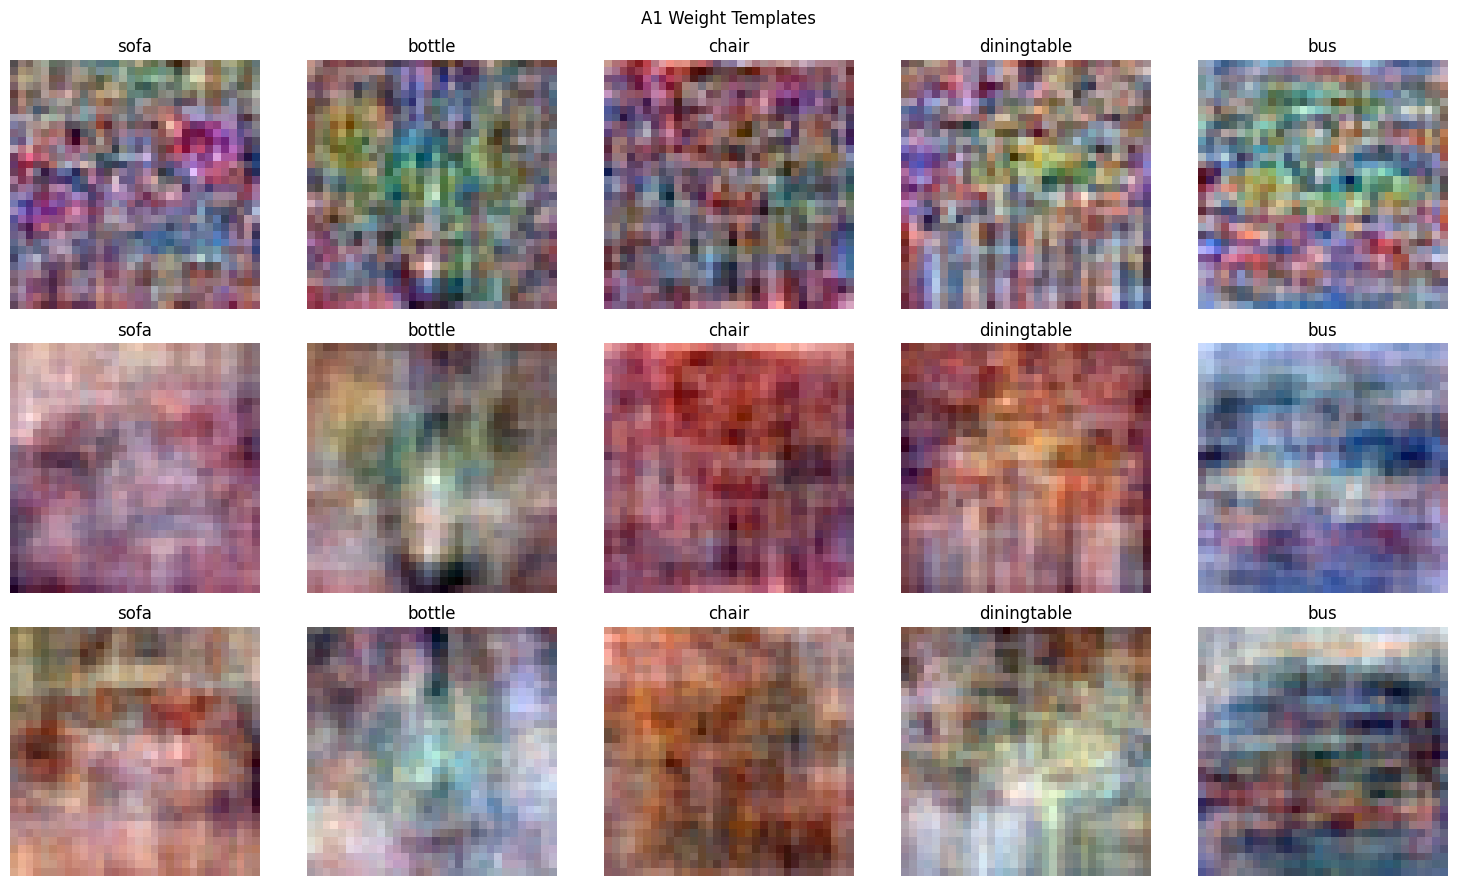

In [7]:
# TODO V1: A1 weights at the three L2 settings, reshaped to 32x32x3 for your five classes, each template scaled to its own
# range, (w - w.min()) / (w.max() - w.min()); validation accuracy of each. Above them, each class's mean training crop minus
# the mean of all training crops. Describe how the weights change across the settings, and whether the most readable is the most accurate.
# Functions: layer.weight.detach().cpu().numpy(); w.reshape(32, 32, 3); (w - w.min()) / (w.max() - w.min());
#    X[idx_train][y[idx_train] == c].mean(axis=0); plt.subplots(rows, cols); ax.imshow
import matplotlib.pyplot as plt
import numpy as np
import torch
import cv2

my_class = ['sofa', 'bottle', 'chair', 'diningtable', 'bus']
l2_value = [0.01, 1, 10]

# Resize images to 32x32
X32 = np.stack([
    cv2.resize(im, (32, 32), interpolation=cv2.INTER_AREA)
    for im in X64
])

overall_mean = X32[idx_train].mean(axis=0)

# Get class labels
class_names = [
    'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus',
    'car', 'cat', 'chair', 'cow', 'diningtable', 'dog',
    'horse', 'motorbike', 'pottedplant', 'sheep', 'sofa',
    'train', 'tvmonitor'
]

# Plot class mean differences
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, name in enumerate(my_class):
    c = class_names.index(name)

    mean_image = X32[idx_train][y[idx_train] == c].mean(axis=0)

    diff = mean_image - overall_mean
    diff = (diff - diff.min()) / (diff.max() - diff.min())

    axes[i].imshow(diff)
    axes[i].set_title(name)
    axes[i].axis('off')

plt.suptitle("Class Mean Differences")
plt.tight_layout()
plt.show()


# Plot A1 weight templates for three L2 settings
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for row, l2 in enumerate(l2_value):

    model = nn.Linear(3072, 19).to(DEV)
    model.load_state_dict(
        torch.load(
            os.path.join(CKPT_DIR, f"a1_l2_{l2:g}.pt"),
            map_location=DEV
        )
    )

    weights = model.weight.detach().cpu().numpy()

    for col, name in enumerate(my_class):
        c = class_names.index(name)

        w = weights[c].reshape(32, 32, 3)
        w = (w - w.min()) / (w.max() - w.min() + 1e-8)

        axes[row, col].imshow(w)
        axes[row, col].set_title(name)
        axes[row, col].axis('off')

    axes[row, 0].set_ylabel(f"L2 = {l2}", fontsize=12)

plt.suptitle("A1 Weight Templates")
plt.tight_layout()
plt.show()

In [8]:

import numpy as np
import torch

val_accuracies_l2 = {}

for l2, model in a1_models.items():
    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, len(idx_val), 256):
            ids = idx_val[start:start + 256]

            x = torch.from_numpy(
                X32_std[ids].reshape(len(ids), -1)
            ).float().to(DEV)

            predictions.append(
                model(x).argmax(dim=1).cpu().numpy()
            )

    predictions = np.concatenate(predictions)
    labels = np.asarray(y)[idx_val]

    class_accuracies = [
        np.mean(predictions[labels == c] == c)
        for c in range(19)
        if np.any(labels == c)
    ]

    val_accuracies_l2[l2] = float(np.mean(class_accuracies))

    print(
        f"L2={l2}: Validation accuracy = "
        f"{val_accuracies_l2[l2]:.4f}"
    )

best_l2 = max(val_accuracies_l2, key=val_accuracies_l2.get)

print("Best L2:", best_l2)


L2=0.01: Validation accuracy = 0.2455
L2=1: Validation accuracy = 0.1899
L2=10: Validation accuracy = 0.1326
Best L2: 0.01


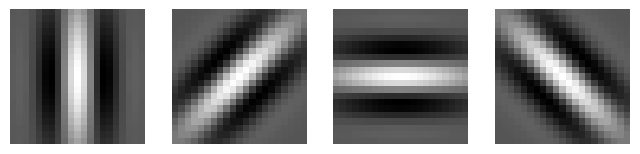

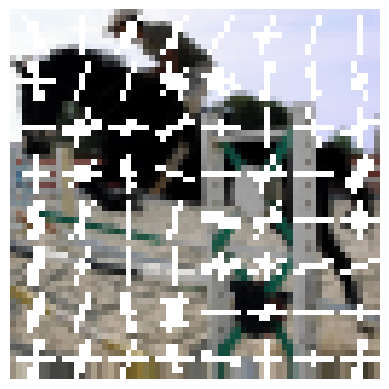

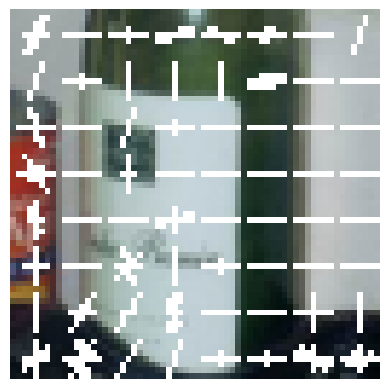

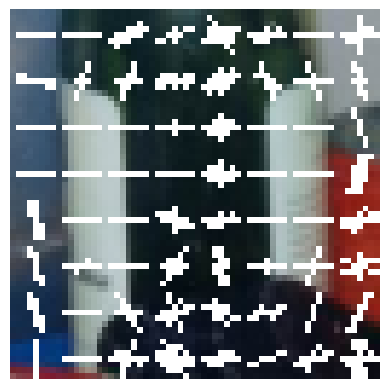

In [9]:
# TODO V2: the Gabor bank, and HOG cell-orientation histograms drawn over three VOC crops. Compute the per-cell histograms
# yourself (cv2.Sobel, cv2.cartToPolar, np.bincount over 8x8 cells): cv2.HOGDescriptor returns one long vector.
# Functions: cv2.getGaborKernel; cv2.Sobel(gray, cv2.CV_32F, 1, 0); cv2.cartToPolar(gx, gy, angleInDegrees=True);
#    np.bincount(bins, weights=mag, minlength=9); cv2.line
# Gabor bank
# HOG over three VOC crops (excluding person crops)
# Gabor bank
gabor_bank = []

for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
    kernel = cv2.getGaborKernel((21, 21), 4, theta, 10, 0.5, 0)
    gabor_bank.append(kernel)

plt.figure(figsize=(8, 4))
for i, kernel in enumerate(gabor_bank):
    plt.subplot(1, 4, i+1)
    plt.imshow(kernel, cmap='gray')
    plt.axis('off')
plt.show()


# HOG over three VOC crops
for idx in idx_train[:3]:
    img = X64[idx]
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)
    mag, angle = cv2.cartToPolar(gx, gy, angleInDegrees=True)

    bins = (angle % 180 / 20).astype(int)
    hog_img = img.copy()

    for y in range(0, 64, 8):
        for x in range(0, 64, 8):
            hist = np.bincount(
                bins[y:y+8, x:x+8].ravel(),
                weights=mag[y:y+8, x:x+8].ravel(),
                minlength=9
            )

            for b in range(9):
                length = hist[b] / (hist.max() + 1e-6) * 4
                a = np.deg2rad(b * 20 + 10)
                dx = int(length * np.cos(a))
                dy = int(length * np.sin(a))

                cv2.line(
                    hog_img,
                    (x+4-dx, y+4-dy),
                    (x+4+dx, y+4+dy),
                    (255, 255, 255), 1
                )

    plt.figure()
    plt.imshow(hog_img)
    plt.axis('off')
    plt.show()

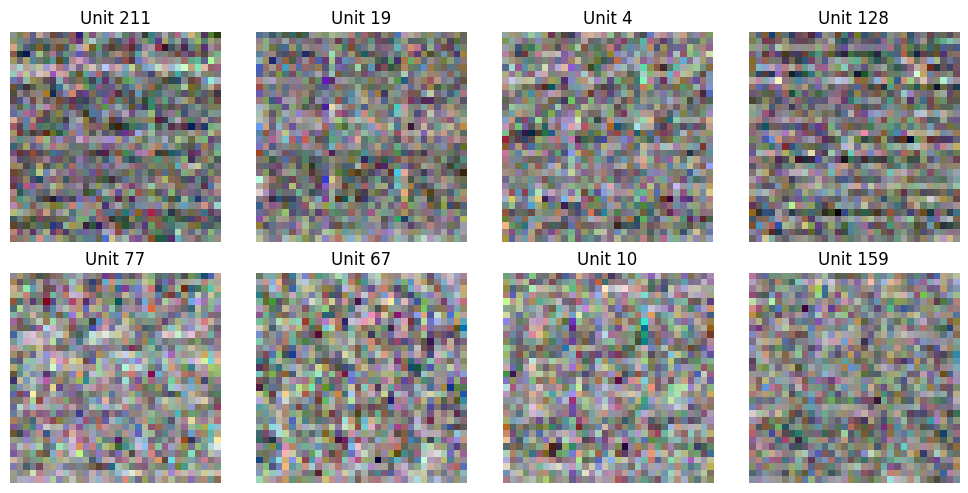

In [10]:
# TODO V3: eight first-layer MLP units, chosen with a fixed seed before you look, reshaped to RGB images. Compare with V1 and
# with A3's learning curves: class templates, or fits to individual training images?
# Functions: np.random.default_rng(0).choice(256, 8, replace=False); layer.weight.detach().cpu().numpy()
# V3: Visualize eight first-layer MLP units
# Load the trained A3 model
# TODO V3: Visualize eight first-layer MLP units

# Define A3
class A3(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3072, 256),
            nn.ReLU(),
            nn.Linear(256, 19)
        )

    def forward(self, x):
        return self.net(x.flatten(1))


# Load trained A3 model
a3_model = A3().to(DEV)
a3_model.load_state_dict(torch.load(
    os.path.join(CKPT_DIR, "a3.pt"),
    map_location=DEV
))
a3_model.eval()

# Select eight units
units = np.random.default_rng(0).choice(256, 8, replace=False)

# Get first-layer weights
weights = a3_model.net[0].weight.detach().cpu().numpy()

# Display the eight units
plt.figure(figsize=(10, 5))

for i, unit in enumerate(units):
    w = weights[unit].reshape(32, 32, 3)
    w = (w - w.min()) / (w.max() - w.min() + 1e-8)

    plt.subplot(2, 4, i + 1)
    plt.imshow(w)
    plt.title(f"Unit {unit}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [11]:
print("A4 exists:", "A4" in globals())
print("A5 exists:", "A5" in globals())
import os
print(os.path.exists(os.path.join(ROOT, "my_models.py")))

A4 exists: False
A5 exists: False
True


In [12]:
# TODO V4: (a) eight A4 first-layer kernels chosen with a fixed seed, after training and as final minus initial weights, beside
# the Gabor bank and the first eight ImageNet ResNet-18 first-layer kernels (each kernel gray at zero: 0.5 + 0.5 * w / abs(w).max());
# (b) three channels per residual stage for one of your photos (channels chosen with a fixed seed);
# (c) for the same channels, the four training crops without people (not HAS_PERSON) with the highest spatial mean of the
# post-ReLU stage activation (36 crops).
# Functions: torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1);
#    r18.conv1.weight; load_photo(path, 64); stage.register_forward_hook(fn); act.mean(dim=(2, 3)); np.argsort
# A4 architecture copied from P1_A

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return F.relu(out)


class A4(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 7, stride=1, padding=3, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )

        self.stage1 = nn.Sequential(
            BasicBlock(32, 32),
            BasicBlock(32, 32)
        )

        self.stage2 = nn.Sequential(
            BasicBlock(32, 64, stride=2),
            BasicBlock(64, 64)
        )

        self.stage3 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128)
        )

        self.fc = nn.Linear(128, 19)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = x.mean(dim=(2, 3))
        return self.fc(x)


# Load trained A4
model_a4 = A4().to(DEV)

model_a4.load_state_dict(
    torch.load(
        os.path.join(CKPT_DIR, "a4.pt"),
        map_location=DEV,
        weights_only=True
    )
)

model_a4.eval()

print("A4 loaded successfully!")

A4 loaded successfully!


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


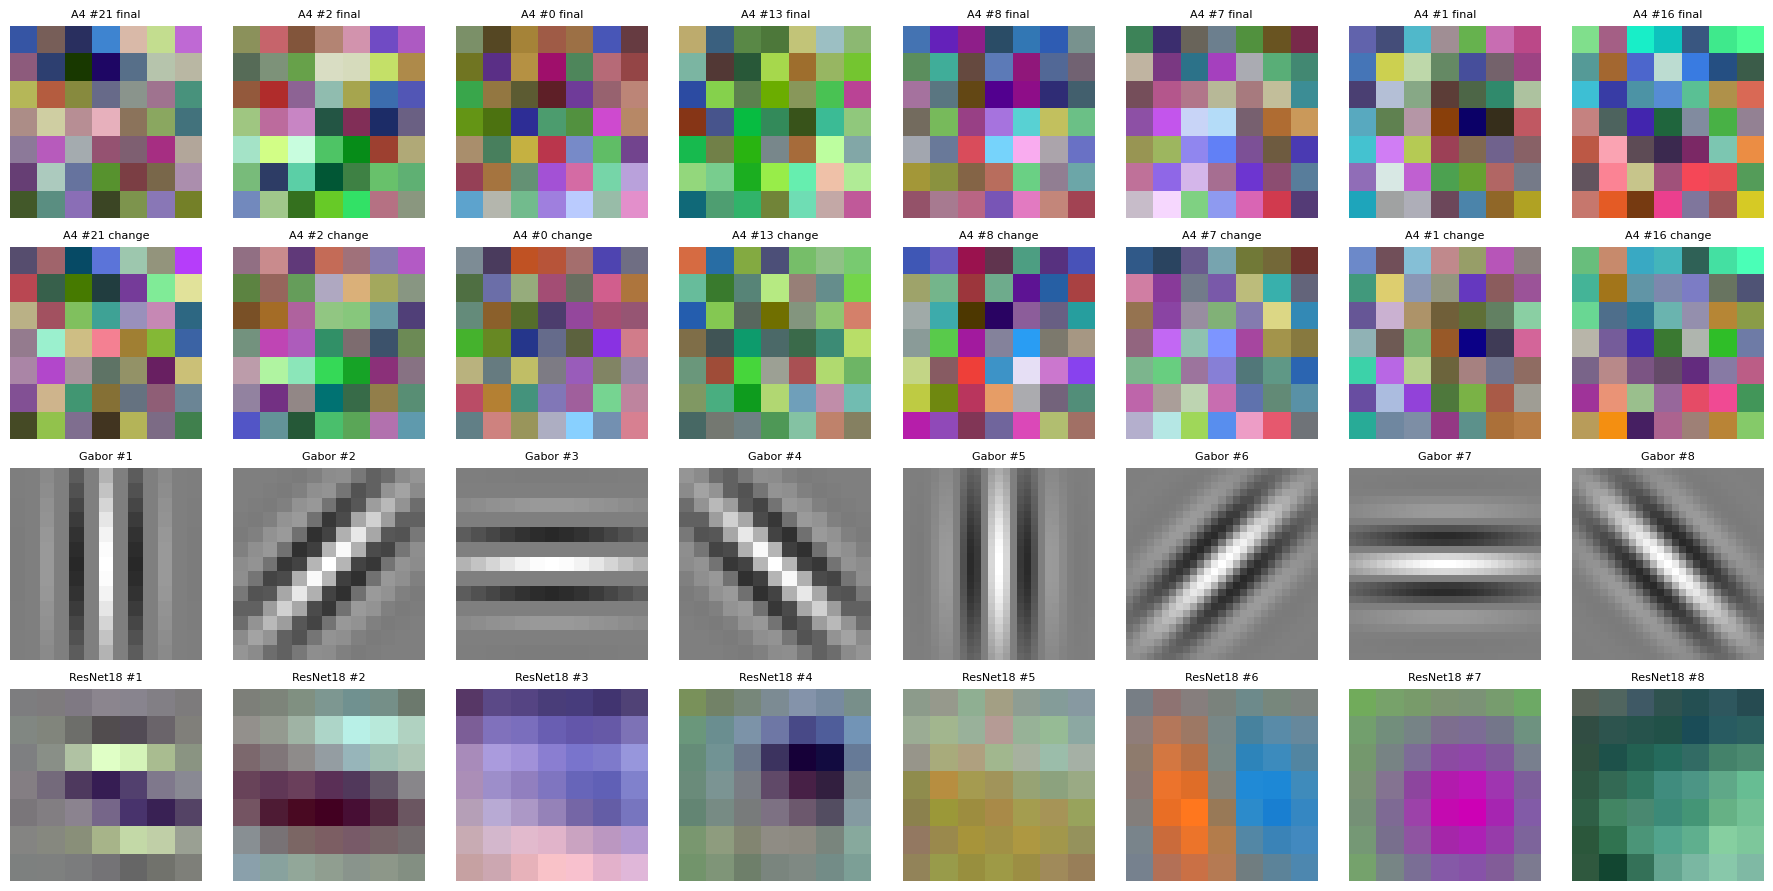

Final kernels: (32, 3, 7, 7)
Initial kernels: (32, 3, 7, 7)
Weight change: (32, 3, 7, 7)


In [13]:

import os
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
import cv2

model_a4.eval()

final_kernels = (
    model_a4.stem[0]
    .weight.detach()
    .cpu()
    .numpy()
    .copy()
)

torch.manual_seed(0)

initial_model = A4()

initial_kernels = (
    initial_model.stem[0]
    .weight.detach()
    .cpu()
    .numpy()
    .copy()
)

weight_change = final_kernels - initial_kernels

rng = np.random.default_rng(0)
selected = rng.choice(32, 8, replace=False)

r18 = torchvision.models.resnet18(
    weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1
)

r18_kernels = (
    r18.conv1.weight.detach().cpu().numpy()[:8]
)

gabor_bank = []

for lambd, ks in [(4, 13), (8, 27)]:
    for k in range(4):
        kern = cv2.getGaborKernel(
            (ks, ks),
            0.56 * lambd,
            k * np.pi / 4,
            lambd,
            0.5,
            0,
            ktype=cv2.CV_32F
        )
        gabor_bank.append(kern - kern.mean())

def show_kernel(ax, w, title):
    w = w / (np.abs(w).max() + 1e-8)
    w = 0.5 + 0.5 * w

    if w.ndim == 3:
        w = np.transpose(w, (1, 2, 0))
        ax.imshow(np.clip(w, 0, 1))
    else:
        ax.imshow(
            np.clip(w, 0, 1),
            cmap="gray",
            vmin=0,
            vmax=1
        )

    ax.set_title(title, fontsize=8)
    ax.axis("off")

fig, axes = plt.subplots(
    4, 8,
    figsize=(18, 9)
)

for j, idx in enumerate(selected):
    show_kernel(
        axes[0, j],
        final_kernels[idx],
        f"A4 #{idx} final"
    )

    show_kernel(
        axes[1, j],
        weight_change[idx],
        f"A4 #{idx} change"
    )

    show_kernel(
        axes[2, j],
        gabor_bank[j],
        f"Gabor #{j + 1}"
    )

    show_kernel(
        axes[3, j],
        r18_kernels[j],
        f"ResNet18 #{j + 1}"
    )

axes[0, 0].set_ylabel("A4 final", fontsize=10)
axes[1, 0].set_ylabel("Final - initial", fontsize=10)
axes[2, 0].set_ylabel("Gabor", fontsize=10)
axes[3, 0].set_ylabel("ImageNet ResNet18", fontsize=10)

plt.tight_layout()
plt.show()

print("Final kernels:", final_kernels.shape)
print("Initial kernels:", initial_kernels.shape)
print("Weight change:", weight_change.shape)


In [14]:
#load A5
class A5(nn.Module):
    def __init__(self):
        super().__init__()

        self.patch_embed = nn.Conv2d(3, 128, kernel_size=8, stride=8)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, 128))
        self.pos_embed = nn.Parameter(torch.zeros(1, 65, 128))

        layer = nn.TransformerEncoderLayer(
            128,
            4,
            512,
            dropout=0.0,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer, 4, enable_nested_tensor=False
        )

        self.norm = nn.LayerNorm(128)
        self.fc = nn.Linear(128, 19)

    def forward(self, x):
        x = self.patch_embed(x)
        x = x.flatten(2).transpose(1, 2)

        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat([cls, x], dim=1)

        x = x + self.pos_embed
        x = self.transformer(x)

        x = self.norm(x[:, 0])
        x = self.fc(x)

        return x
model_a5 = A5().to(DEV)

model_a5.load_state_dict(
    torch.load(
        os.path.join(CKPT_DIR, "a5.pt"),
        map_location=DEV,
        weights_only=True
    )
)

model_a5.eval()

print("A5 loaded successfully!")

A5 loaded successfully!


A5 patch size: 8 explained variance: [3.04 2.39 2.37 2.31 2.24 2.15]
A6-H patch size: 16 explained variance: [4.96 2.69 2.22 2.19 1.69 1.67]


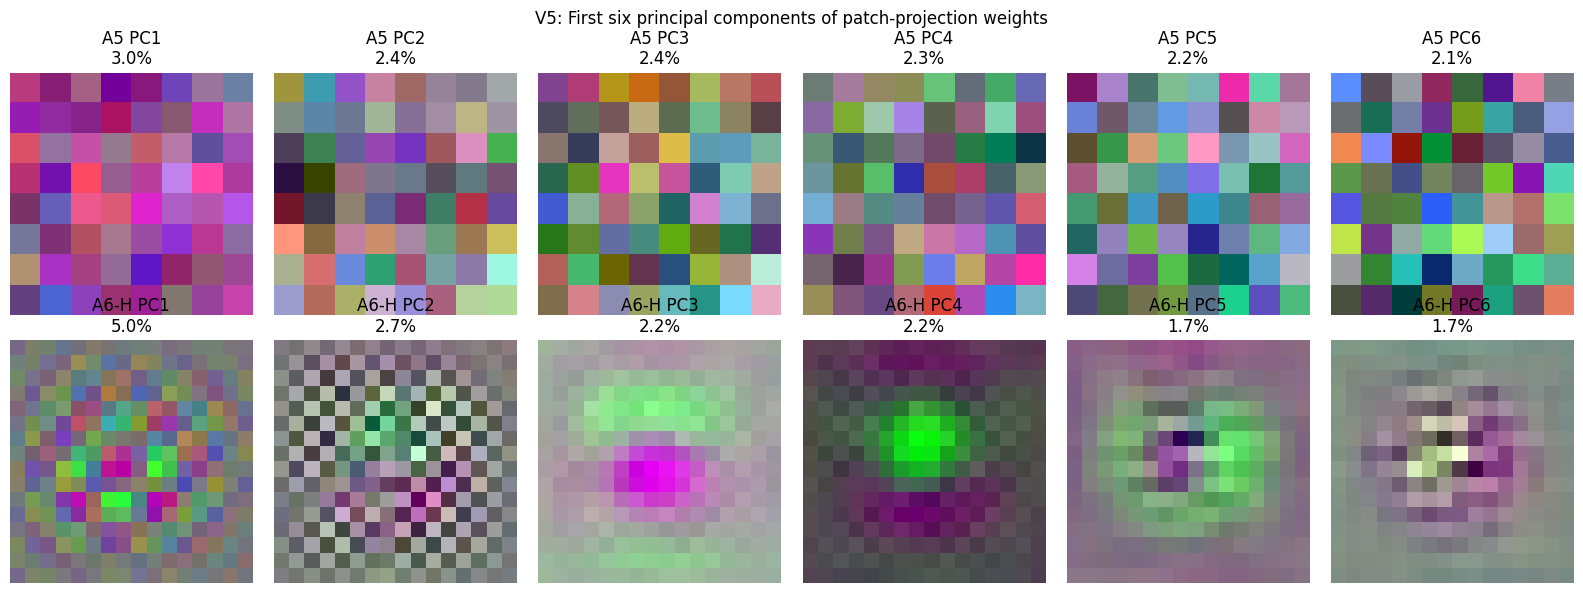

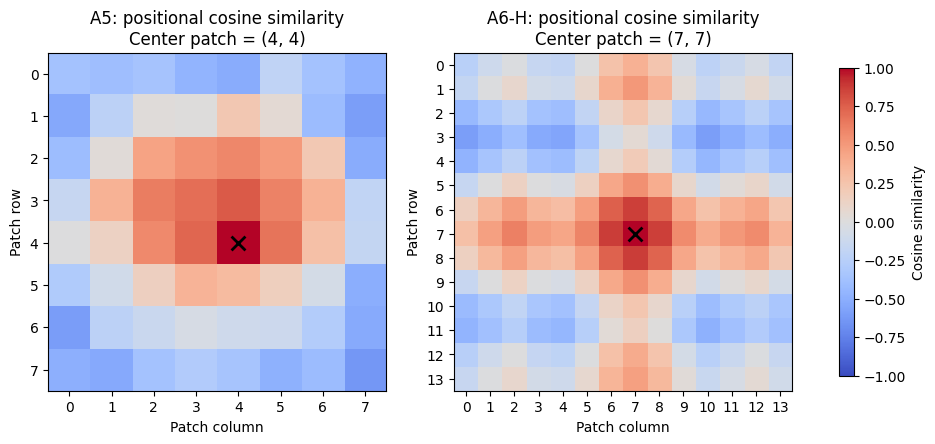


A5
Grid: (8, 8)
Central patch: (4, 4)
Center similarity: 0.99999994
Minimum similarity: -0.63470775
Maximum similarity: 0.99999994
Mean similarity: -0.03966149

A6-H
Grid: (14, 14)
Central patch: (7, 7)
Center similarity: 1.0000001
Minimum similarity: -0.60123205
Maximum similarity: 1.0000001
Mean similarity: 0.025470305


In [15]:
# TODO V5 (hint: a CNN has local filters and 2D layout built in; a ViT must learn both. Did A5 and A6-H?):
# for A5 and A6-H, the first six principal components of the patch-projection weights (flatten each output
# channel's filter into a row of length 3*p*p, center the columns, show the top six directions as p x p RGB patches), and the
# cosine similarity of a central patch's position embedding (give its grid coordinates) to all others (class token excluded).
# Functions: model.patch_embed.proj.weight; model.pos_embed; np.linalg.svd(W - W.mean(0), full_matrices=False);
#    F.cosine_similarity(a, b, dim=-1)

import os
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import timm

DEV = "cuda" if torch.cuda.is_available() else "cpu"

CKPT_DIR = "/content/drive/MyDrive/p1/checkpoints"

if "model_a5" not in globals():
    if "A5" not in globals():
        raise RuntimeError("Run the A5 model definition cell first")

    model_a5 = A5().to(DEV)

    model_a5.load_state_dict(
        torch.load(
            os.path.join(CKPT_DIR, "a5.pt"),
            map_location=DEV,
            weights_only=True
        )
    )

model_a5 = model_a5.to(DEV).eval()

if "model_a6h" not in globals():
    model_a6h = timm.create_model(
        "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
        pretrained=False,
        num_classes=19
    ).to(DEV)

    model_a6h.load_state_dict(
        torch.load(
            os.path.join(CKPT_DIR, "a6_h.pt"),
            map_location=DEV,
            weights_only=True
        )
    )

model_a6h = model_a6h.to(DEV).eval()

def get_patch_weights(model):
    patch_embed = model.patch_embed

    if hasattr(patch_embed, "proj"):
        weights = patch_embed.proj.weight
    else:
        weights = patch_embed.weight

    return weights.detach().cpu().numpy()

def get_position_embeddings(model):
    return model.pos_embed.detach().cpu()

def normalize_rgb(patch):
    minimum = patch.min()
    maximum = patch.max()

    if maximum > minimum:
        return (patch - minimum) / (maximum - minimum)

    return np.zeros_like(patch)

def compute_patch_pca(model):
    weights = get_patch_weights(model)

    channels, colors, patch_h, patch_w = weights.shape

    if colors != 3 or patch_h != patch_w:
        raise ValueError("Expected square RGB patch filters")

    W = weights.reshape(channels, -1)
    W_centered = W - W.mean(axis=0, keepdims=True)

    U, S, Vt = np.linalg.svd(
        W_centered,
        full_matrices=False
    )

    components = []

    for i in range(6):
        component = Vt[i].reshape(3, patch_h, patch_w)
        component = np.transpose(component, (1, 2, 0))
        components.append(normalize_rgb(component))

    variance = S ** 2
    explained = variance[:6] / variance.sum()

    return components, explained, patch_h

def compute_position_similarity(model):
    pos = get_position_embeddings(model)

    if pos.ndim == 3:
        pos = pos[0]

    pos = pos[1:]

    number_of_patches = pos.shape[0]
    grid_size = int(np.sqrt(number_of_patches))

    if grid_size ** 2 != number_of_patches:
        raise ValueError("Position embeddings do not form a square grid")

    center_row = grid_size // 2
    center_col = grid_size // 2

    center_index = center_row * grid_size + center_col

    center_embedding = pos[center_index]

    similarity = F.cosine_similarity(
        pos,
        center_embedding.unsqueeze(0),
        dim=-1
    )

    similarity_map = similarity.reshape(
        grid_size, grid_size
    ).numpy()

    return similarity_map, center_row, center_col

models = {
    "A5": model_a5,
    "A6-H": model_a6h
}

fig, axes = plt.subplots(
    2, 6,
    figsize=(16, 6)
)

for row, (name, model) in enumerate(models.items()):
    components, explained, patch_size = compute_patch_pca(model)

    for col in range(6):
        axes[row, col].imshow(
            components[col],
            interpolation="nearest"
        )

        axes[row, col].set_title(
            f"{name} PC{col + 1}\n"
            f"{explained[col] * 100:.1f}%"
        )

        axes[row, col].axis("off")

    print(
        name,
        "patch size:",
        patch_size,
        "explained variance:",
        np.round(explained * 100, 2)
    )

plt.suptitle(
    "V5: First six principal components of patch-projection weights"
)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, (name, model) in zip(axes, models.items()):
    similarity, center_row, center_col = compute_position_similarity(model)

    im = ax.imshow(
        similarity,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        interpolation="nearest"
    )

    ax.scatter(
        center_col,
        center_row,
        marker="x",
        color="black",
        s=100,
        linewidths=2
    )

    ax.set_title(
        f"{name}: positional cosine similarity\n"
        f"Center patch = ({center_row}, {center_col})"
    )

    ax.set_xlabel("Patch column")
    ax.set_ylabel("Patch row")

    ax.set_xticks(range(similarity.shape[1]))
    ax.set_yticks(range(similarity.shape[0]))

fig.colorbar(
    im,
    ax=axes,
    shrink=0.8,
    label="Cosine similarity"
)

plt.show()

for name, model in models.items():
    similarity, center_row, center_col = compute_position_similarity(model)

    print(f"\n{name}")
    print("Grid:", similarity.shape)
    print("Central patch:", (center_row, center_col))
    print("Center similarity:", similarity[center_row, center_col])
    print("Minimum similarity:", similarity.min())
    print("Maximum similarity:", similarity.max())
    print("Mean similarity:", similarity.mean())
